# How much do we collapse? Sensitivity of the Truvari event definition

arch3 stores one panel record per assembly path through a pangenome bubble, so one insertion can be
several records. We merge records into **events** with `truvari collapse` matching, *inside each bubble,
per type (insertion / deletion)*: two alleles merge if

- size similarity `min/max` >= **pctsize** (default 0.95),
- sequence similarity `(lenA + lenB - editdist) / (lenA + lenB)` >= **pctseq** (default 0.95; edlib on the
  inserted/deleted sequence, second sequence rotated by the position offset),
- `|POS_A - POS_B|` <= **refdist** (default 500 bp),

greedy, no chaining, representative = earliest position (`keep=first`). Code: `_build_event_map.py`;
this notebook re-runs the same functions over a parameter grid (`truvari_sweep.py`). The default setting
reproduces the saved `arch3_event_map.npz` exactly (checked in the sweep logs).

SV = |ref length - alt length| > 50 bp, all five chromosomes.

In [1]:

import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sys
G = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection"; SA = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection/r1_sv_negative_selection/results/sv_adaptive"; PLOTS = f"{G}/notebooks/plots"
sys.path.insert(0, f"{G}/genes/convergence")
import plot_theme as TH
TH.apply(); plt.rcParams['figure.dpi'] = 120
from matplotlib.colors import LinearSegmentedColormap
GREENRAMP = LinearSegmentedColormap.from_list('g', ['#CFE8CF', '#8CC98C', '#3F9B49', '#1B5E20'])
sw = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f"{SA}/truvari_sweep_Chr*.csv"))], ignore_index=True)
print("chromosomes:", sorted(sw.chrom.unique()))
key = ['factor','pctseq','pctsize','refdist','keep']
tot = sw.groupby(key, as_index=False).agg(n_events=('n_events','sum'), n_ins=('n_ins','sum'), n_del=('n_del','sum'),
        n_records=('n_records','sum'), n_bubbles=('n_bubbles','sum'), seconds=('seconds','sum'),
        max_members=('max_members','max'))
tot['_o'] = (tot.factor != 'default').astype(int)   # the default setting is also a grid / refdist point: keep one copy
tot = tot.sort_values('_o').drop_duplicates(['pctseq','pctsize','refdist','keep']).drop(columns='_o').reset_index(drop=True)
N_REC, N_BUB = int(tot.n_records.iloc[0]), int(tot.n_bubbles.iloc[0])
tot['records_per_event'] = N_REC / tot.n_events
print(f"{N_REC:,} SV records -> {N_BUB:,} bubbles (upper bound on collapse); records = no collapse")
dflt = tot[(tot.pctseq==0.95)&(tot.pctsize==0.95)&(tot.refdist==500)&(tot.keep=='first')].iloc[0]
print(f"DEFAULT (0.95/0.95/500/first): {int(dflt.n_events):,} events = {dflt.records_per_event:.2f} records per event; "
      f"collapsed {100*(1-dflt.n_events/N_REC):.1f}% of records; {dflt.n_events/N_BUB:.2f} events per bubble")


chromosomes: ['Chr1', 'Chr2', 'Chr3', 'Chr4', 'Chr5']
226,468 SV records -> 43,935 bubbles (upper bound on collapse); records = no collapse
DEFAULT (0.95/0.95/500/first): 89,940 events = 2.52 records per event; collapsed 60.3% of records; 2.05 events per bubble


## Reference points already used downstream

In [2]:

# the three event maps already used downstream, for reference
ref = {}
for name, f in (("bubble (no splitting)", "arch3_bubble_map.npz"), ("truvari default 0.95/0.95", "arch3_event_map.npz"),
                ("truvari bench 0.7/0.7, keep=common", "arch3_event_map_bench07.npz"), ("strict (15-mer Jaccard)", "arch3_event_map_strict.npz")):
    z = np.load(f"{SA}/{f}", allow_pickle=True)
    ref[name] = sum(np.unique(z[k[:-4]+'_bubble']).size for k in z.files if k.endswith('_rec'))
ref = pd.Series({'records (alleles)': N_REC, **ref}, name='units'); ref.to_frame()


,units
records (alleles),226468
bubble (no splitting),43935
truvari default 0.95/0.95,89940
"truvari bench 0.7/0.7, keep=common",77033
strict (15-mer Jaccard),90543


## pctseq x pctsize (refdist 500, keep = first): collapse builds up as the thresholds are relaxed

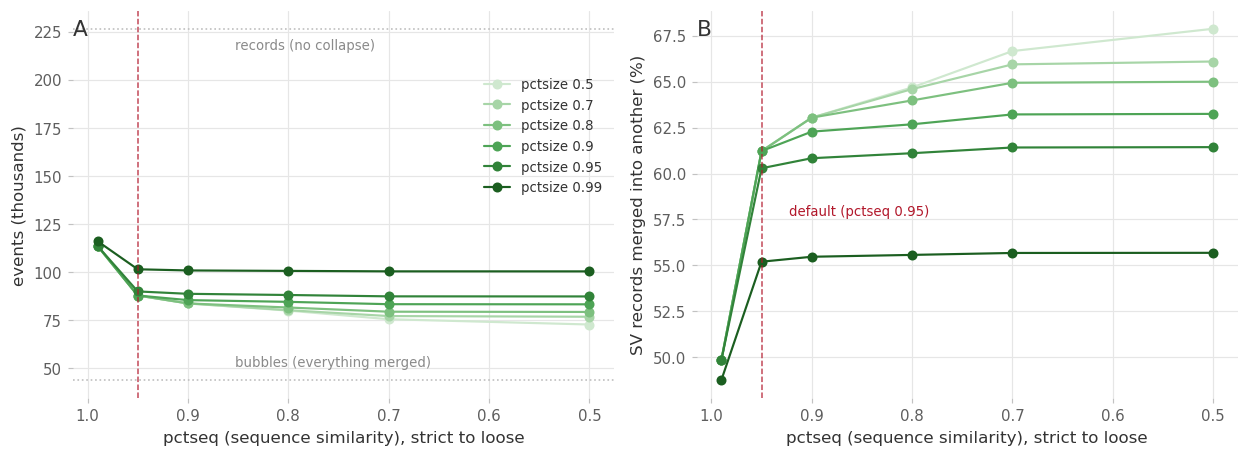

pctsize,0.50,0.70,0.80,0.90,0.95,0.99
pctseq,,,,,,
0.99,113549,113549,113549,113549,113549,116023
0.95,87823,87823,87823,87823,89940,101454
0.90,83702,83702,83702,85427,88702,100844
0.80,79978,80186,81581,84524,88085,100616
0.70,75499,77137,79405,83306,87381,100377
0.50,72751,76786,79276,83240,87337,100360


In [3]:


g = tot[tot.factor.isin(['grid','default']) & (tot.refdist==500) & (tot.keep=='first')]
P = g.pivot(index='pctseq', columns='pctsize', values='n_events').sort_index(ascending=False).sort_index(axis=1)
sizes = list(P.columns); cm = GREENRAMP(np.linspace(0.0, 1.0, len(sizes)))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharex=True)
for c, z in zip(cm, sizes):
    axes[0].plot(P.index, P[z]/1000, marker='o', ms=5, lw=1.3, color=c, label=f"pctsize {z}")
    axes[1].plot(P.index, 100*(1 - P[z]/N_REC), marker='o', ms=5, lw=1.3, color=c)
axes[0].axhline(N_REC/1000, color=TH.FAINT, ls=':', lw=1); TH.note(axes[0], 'records (no collapse)', y=0.93, x=0.30)
axes[0].axhline(N_BUB/1000, color=TH.FAINT, ls=':', lw=1); TH.note(axes[0], 'bubbles (everything merged)', y=0.11, x=0.30)
for ax in axes:
    ax.axvline(0.95, color=TH.ACCENT, lw=0.9, ls='--', alpha=0.8)
    ax.set_xlabel('pctseq (sequence similarity), strict to loose')
axes[0].invert_xaxis()                       # shared x: strict (0.99) left, loose (0.5) right
axes[0].set_ylabel('events (thousands)'); axes[1].set_ylabel('SV records merged into another (%)')
axes[0].legend(loc='upper right', bbox_to_anchor=(1.0, 0.86), title=None)
TH.note(axes[1], 'default (pctseq 0.95)', y=0.50, x=0.17, color=TH.ACCENT)
TH.panel(axes[0], 'A'); TH.panel(axes[1], 'B')
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_sweep_grid.png", dpi=200); plt.show()
P.astype(int)



## One factor at a time, and run time

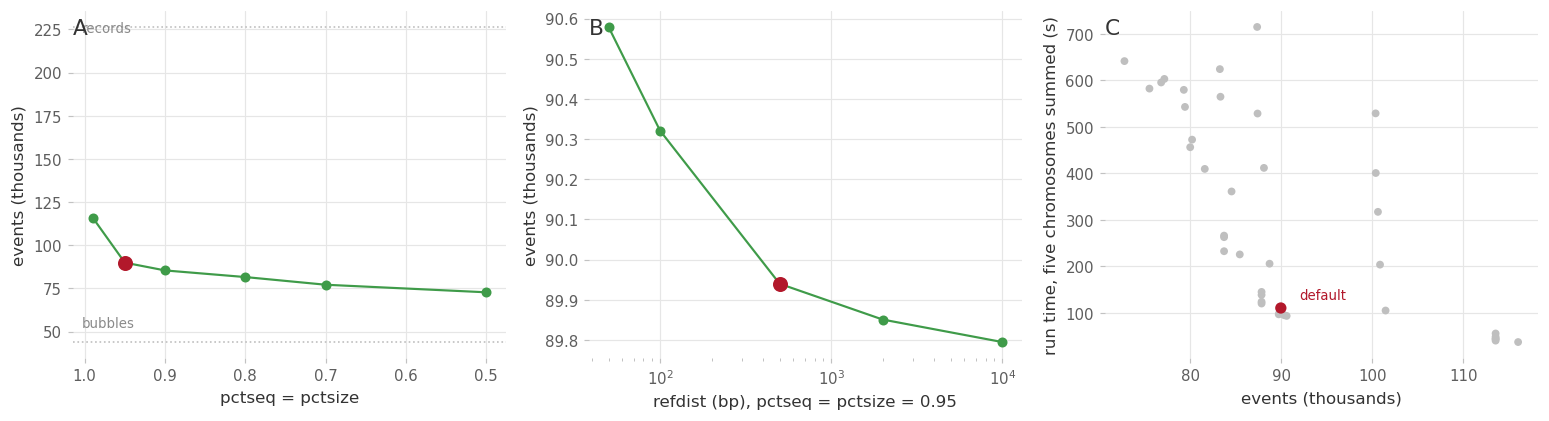

,factor,pctseq,pctsize,refdist,keep,n_events,n_ins,n_del,records_per_event,seconds
0,default,0.95,0.95,500,first,89940,50231,39709,2.52,110.22
14,keep,0.95,0.95,500,common,89710,50044,39666,2.52,96.59
15,refdist,0.95,0.95,50,first,90579,50475,40104,2.50,93.21
16,refdist,0.95,0.95,100,first,90321,50373,39948,2.51,94.68
18,refdist,0.95,0.95,2000,first,89851,50207,39644,2.52,98.58
40,refdist,0.95,0.95,10000,first,89795,50193,39602,2.52,100.54


In [4]:


fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
a = tot[(tot.factor.isin(['grid','default'])) & (tot.pctseq==tot.pctsize) & (tot.refdist==500) & (tot.keep=='first')].sort_values('pctseq')
axes[0].plot(a.pctseq, a.n_events/1000, marker='o', ms=5, lw=1.3, color=TH.GREENS[1])
axes[0].plot(0.95, float(a[a.pctseq==0.95].n_events.iloc[0])/1000, 'o', ms=8, color=TH.ACCENT)
axes[0].axhline(N_REC/1000, color=TH.FAINT, ls=':', lw=1); TH.note(axes[0], 'records', y=0.97, x=0.02)
axes[0].axhline(N_BUB/1000, color=TH.FAINT, ls=':', lw=1); TH.note(axes[0], 'bubbles', y=0.12, x=0.02)
axes[0].set_xlabel('pctseq = pctsize'); axes[0].set_ylabel('events (thousands)'); axes[0].invert_xaxis()
r = tot[tot.factor.isin(['refdist','default'])].sort_values('refdist')
axes[1].plot(r.refdist, r.n_events/1000, marker='o', ms=5, lw=1.3, color=TH.GREENS[1])
axes[1].plot(500, float(r[r.refdist==500].n_events.iloc[0])/1000, 'o', ms=8, color=TH.ACCENT)
axes[1].set_xscale('log'); axes[1].set_xlabel('refdist (bp), pctseq = pctsize = 0.95'); axes[1].set_ylabel('events (thousands)')
d = tot[tot.factor=='default'].iloc[0]
axes[2].scatter(tot.n_events/1000, tot.seconds, s=22, color=TH.FAINT, edgecolor='none')
axes[2].scatter(d.n_events/1000, d.seconds, s=46, color=TH.ACCENT, edgecolor='none'); TH.note(axes[2], 'default', y=0.2, x=0.45, color=TH.ACCENT)
axes[2].set_xlabel('events (thousands)'); axes[2].set_ylabel('run time, five chromosomes summed (s)')
for ax, l in zip(axes, 'ABC'): TH.panel(ax, l)
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_sweep_one_factor.png", dpi=200); plt.show()
tot[tot.factor.isin(['refdist','keep','default'])][['factor','pctseq','pctsize','refdist','keep','n_events','n_ins','n_del','records_per_event','seconds']].round(2)



## Is the 500 bp `refdist` binding? POS spread inside a bubble

20,573 (bubble, type) groups with >= 2 alleles
count    20573.0
mean      1320.0
std       5643.0
min          0.0
50%          0.0
75%        328.0
90%       2362.0
99%      25820.0
max      98305.0
  groups whose alleles span > 0 bp: 50.0%
  groups whose alleles span > 50 bp: 36.5%
  groups whose alleles span > 500 bp: 21.6%
  groups whose alleles span > 5000 bp: 6.1%


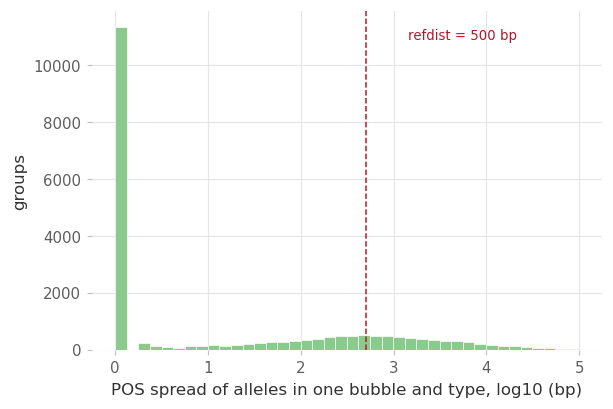

In [5]:


pr = pd.read_csv(f"{SA}/truvari_bubble_pos_range.csv")
print(f"{len(pr):,} (bubble, type) groups with >= 2 alleles")
print(pr.pos_range_bp.describe(percentiles=[.5,.75,.9,.99]).round(0).to_string())
for t in (0, 50, 500, 5000): print(f"  groups whose alleles span > {t} bp: {100*(pr.pos_range_bp > t).mean():.1f}%")
fig, ax = plt.subplots(figsize=(5.2, 3.5))
ax.hist(np.log10(pr.pos_range_bp.clip(lower=1)), bins=40, color=TH.GREENS[0], edgecolor='white', linewidth=0.4)
ax.axvline(np.log10(500), color=TH.ACCENT, lw=0.9, ls='--'); TH.note(ax, 'refdist = 500 bp', y=0.95, x=0.62, color=TH.ACCENT)
ax.set_xlabel('POS spread of alleles in one bubble and type, log10 (bp)'); ax.set_ylabel('groups')
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_bubble_pos_range.png", dpi=200); plt.show()



## Site-frequency spectrum: alleles vs events

Carrier count = founders (of 231) carrying the unit; an event is carried by a founder if it carries ANY member allele. Only 0.61% of founder-event carrier pairs carry two alleles of one event (`_build_event_units.py`), so an event's count is close to the sum of its members' counts: merging moves units from the rare bins into higher-frequency bins.

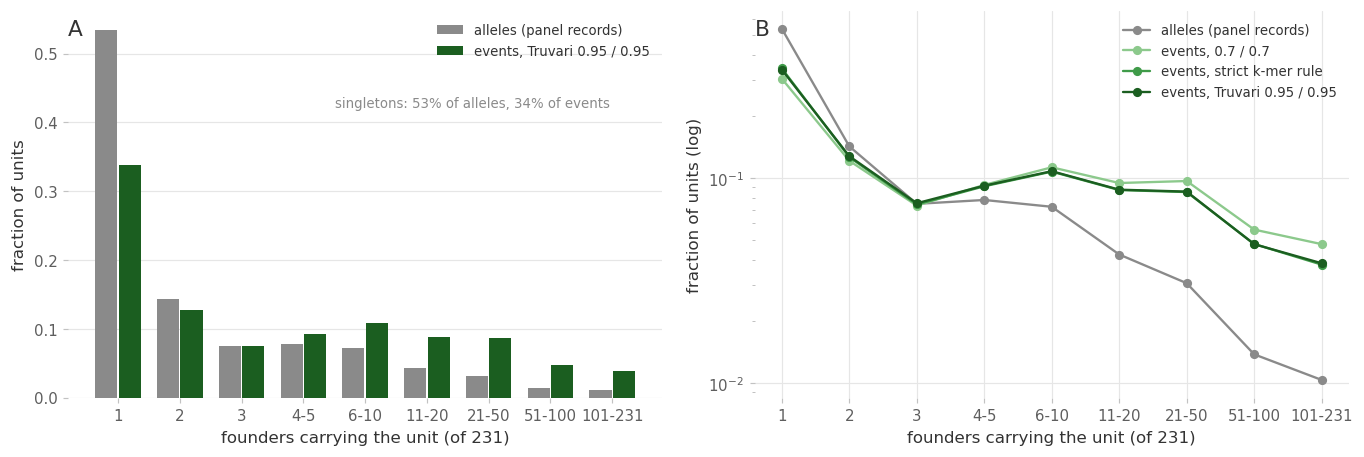

,n_units,singleton_frac,median_carriers,mean_carriers,common_ge_10pct
unit,,,,,
alleles,226468,0.535,1.0,6.036,0.051
truvari_default,89940,0.338,3.0,15.191,0.162
truvari_bench07,77033,0.305,4.0,17.637,0.189
strict,90543,0.342,3.0,15.088,0.161


In [6]:


sf = pd.read_csv(f"{SA}/sv_sfs_alleles_vs_events.csv")
EDGES = [1, 2, 3, 4, 6, 11, 21, 51, 101, 232]
LAB = ['1','2','3','4-5','6-10','11-20','21-50','51-100','101-231']
sf['bin'] = pd.cut(sf.carriers, EDGES, right=False, labels=LAB)
frac = sf.groupby(['unit','bin'], observed=False).size().unstack(0)
frac = frac / frac.sum()
NAMES = {'alleles':'alleles (panel records)', 'truvari_default':'events, Truvari 0.95 / 0.95', 'truvari_bench07':'events, 0.7 / 0.7', 'strict':'events, strict k-mer rule'}
COL = {'alleles':TH.MUTED, 'truvari_default':TH.GREENS[2], 'truvari_bench07':TH.GREENS[0], 'strict':TH.GREENS[1]}
single = sf.groupby('unit').carriers.apply(lambda v: (v==1).mean())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
w = 0.38; x = np.arange(len(LAB))
for u, off in (('alleles', -w/2), ('truvari_default', w/2)):
    axes[0].bar(x + off, frac[u].values, w*0.94, color=COL[u], label=NAMES[u], linewidth=0)
TH.grid_only(axes[0], 'y')
axes[0].set_xticks(x); axes[0].set_xticklabels(LAB); axes[0].set_xlabel('founders carrying the unit (of 231)'); axes[0].set_ylabel('fraction of units')
axes[0].legend(loc='upper right')
TH.note(axes[0], f"singletons: {100*single['alleles']:.0f}% of alleles, {100*single['truvari_default']:.0f}% of events", y=0.78, x=0.45, ha='left')
for u in ('alleles', 'truvari_bench07', 'strict', 'truvari_default'):
    axes[1].plot(x, frac[u].values, marker='o', ms=4.5, lw=1.4, color=COL[u], label=NAMES[u])
axes[1].set_xticks(x); axes[1].set_xticklabels(LAB); axes[1].set_xlabel('founders carrying the unit (of 231)'); axes[1].set_yscale('log')
axes[1].set_ylabel('fraction of units (log)'); axes[1].legend(loc='upper right')
TH.panel(axes[0], 'A'); TH.panel(axes[1], 'B')
fig.tight_layout(); fig.savefig(f"{PLOTS}/truvari_sfs_alleles_vs_events.png", dpi=200); plt.show()
summ = sf.groupby('unit').agg(n_units=('carriers','size'), singleton_frac=('carriers', lambda v: (v==1).mean()),
        median_carriers=('carriers','median'), mean_carriers=('carriers','mean'), common_ge_10pct=('carriers', lambda v: (v>=23).mean())).round(3)
summ.loc[['alleles','truvari_default','truvari_bench07','strict']]



In [7]:

t = sf[sf.unit.isin(['alleles','truvari_default'])].groupby(['unit','type']).agg(n=('carriers','size'),
        singleton_frac=('carriers', lambda v: (v==1).mean()), median_carriers=('carriers','median')).round(3)
t


n  singleton_frac  median_carriers
unit            type                                         
alleles         del    54248           0.408              2.0
                ins   172220           0.575              1.0
truvari_default del    39709           0.322              3.0
                ins    50231           0.350              3.0